In [1]:
import pandas as pd

# CMAPSS column names
cols = [
    "unit_number", "time_in_cycles",
    "operational_setting_1", "operational_setting_2", "operational_setting_3",
    "sensor_1", "sensor_2", "sensor_3", "sensor_4", "sensor_5",
    "sensor_6", "sensor_7", "sensor_8", "sensor_9", "sensor_10",
    "sensor_11", "sensor_12", "sensor_13", "sensor_14", "sensor_15",
    "sensor_16", "sensor_17", "sensor_18", "sensor_19", "sensor_20",
    "sensor_21"
]

train_path = r"../data/raw/cmapss/train_FD001.txt"
test_path = r"../data/raw/cmapss/test_FD001.txt"
rul_path = r"../data/raw/cmapss/RUL_FD001.txt"

train_df = pd.read_csv(train_path, sep=r"\s+", header=None)
test_df = pd.read_csv(test_path, sep=r"\s+", header=None)
rul_df = pd.read_csv(rul_path, sep=r"\s+", header=None)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("RUL shape:", rul_df.shape)

train_df.head()

Train shape: (20631, 26)
Test shape: (13096, 26)
RUL shape: (100, 1)


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [2]:
train_df.columns = cols
test_df.columns = cols

print(train_df.head())
print(train_df.isnull().sum().sum())

   unit_number  time_in_cycles  operational_setting_1  operational_setting_2  \
0            1               1                -0.0007                -0.0004   
1            1               2                 0.0019                -0.0003   
2            1               3                -0.0043                 0.0003   
3            1               4                 0.0007                 0.0000   
4            1               5                -0.0019                -0.0002   

   operational_setting_3  sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  \
0                  100.0    518.67    641.82   1589.70   1400.60     14.62   
1                  100.0    518.67    642.15   1591.82   1403.14     14.62   
2                  100.0    518.67    642.35   1587.99   1404.20     14.62   
3                  100.0    518.67    642.35   1582.79   1401.87     14.62   
4                  100.0    518.67    642.37   1582.85   1406.22     14.62   

   ...  sensor_12  sensor_13  sensor_14  sensor_15

In [3]:
import pandas as pd
import numpy as np

cols = [
    "unit_number", "time_in_cycles",
    "operational_setting_1", "operational_setting_2", "operational_setting_3",
    "sensor_1", "sensor_2", "sensor_3", "sensor_4", "sensor_5",
    "sensor_6", "sensor_7", "sensor_8", "sensor_9", "sensor_10",
    "sensor_11", "sensor_12", "sensor_13", "sensor_14", "sensor_15",
    "sensor_16", "sensor_17", "sensor_18", "sensor_19", "sensor_20",
    "sensor_21"
]

train_path = r"../data/raw/cmapss/train_FD001.txt"
test_path = r"../data/raw/cmapss/test_FD001.txt"
rul_path = r"../data/raw/cmapss/RUL_FD001.txt"

train_df = pd.read_csv(train_path, sep=r"\s+", header=None)
test_df = pd.read_csv(test_path, sep=r"\s+", header=None)
rul_df = pd.read_csv(rul_path, sep=r"\s+", header=None)

train_df.columns = cols
test_df.columns = cols

# RUL for training data
max_cycles = train_df.groupby("unit_number")["time_in_cycles"].max().reset_index()
max_cycles.columns = ["unit_number", "max_cycle"]

train_df = train_df.merge(max_cycles, on="unit_number", how="left")
train_df["RUL"] = train_df["max_cycle"] - train_df["time_in_cycles"]

# Simple binary health label
# 1 = healthy, 0 = degraded
train_df["health_state"] = np.where(train_df["RUL"] > 30, 1, 0)

train_df.drop(columns=["max_cycle"], inplace=True)

print(train_df[["unit_number", "time_in_cycles", "RUL", "health_state"]].head(10))
print("Train shape after labeling:", train_df.shape)

   unit_number  time_in_cycles  RUL  health_state
0            1               1  191             1
1            1               2  190             1
2            1               3  189             1
3            1               4  188             1
4            1               5  187             1
5            1               6  186             1
6            1               7  185             1
7            1               8  184             1
8            1               9  183             1
9            1              10  182             1
Train shape after labeling: (20631, 28)


In [4]:
# Basic check of RUL distribution
print(train_df["RUL"].describe())
print(train_df["health_state"].value_counts())

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64
health_state
1    17531
0     3100
Name: count, dtype: int64


In [5]:
from sklearn.preprocessing import MinMaxScaler

# Drop columns we don't need
drop_cols = [
    "unit_number",
    "time_in_cycles",
    "RUL",
    "health_state"
]

features = train_df.drop(columns=drop_cols)

print("Feature shape:", features.shape)
features.head()

Feature shape: (20631, 24)


,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [6]:
scaler = MinMaxScaler()

scaled_features = scaler.fit_transform(features)

scaled_df = pd.DataFrame(scaled_features, columns=features.columns)

print(scaled_df.head())

   operational_setting_1  operational_setting_2  operational_setting_3  \
0               0.459770               0.166667                    0.0   
1               0.609195               0.250000                    0.0   
2               0.252874               0.750000                    0.0   
3               0.540230               0.500000                    0.0   
4               0.390805               0.333333                    0.0   

   sensor_1  sensor_2  sensor_3  sensor_4  sensor_5  sensor_6  sensor_7  ...  \
0       0.0  0.183735  0.406802  0.309757       0.0       1.0  0.726248  ...   
1       0.0  0.283133  0.453019  0.352633       0.0       1.0  0.628019  ...   
2       0.0  0.343373  0.369523  0.370527       0.0       1.0  0.710145  ...   
3       0.0  0.343373  0.256159  0.331195       0.0       1.0  0.740741  ...   
4       0.0  0.349398  0.257467  0.404625       0.0       1.0  0.668277  ...   

   sensor_12  sensor_13  sensor_14  sensor_15  sensor_16  sensor_17  \
0  

In [7]:
# Sequence length (very important hyperparameter)
SEQ_LENGTH = 30

def create_sequences(data, unit_ids, seq_length):
    sequences = []
    
    for unit in unit_ids:
        unit_data = data[train_df["unit_number"] == unit]
        unit_data = unit_data.values
        
        for i in range(len(unit_data) - seq_length):
            seq = unit_data[i:i+seq_length]
            sequences.append(seq)
    
    return np.array(sequences)

unit_ids = train_df["unit_number"].unique()

X_train = create_sequences(scaled_df, unit_ids, SEQ_LENGTH)

print("Sequence shape:", X_train.shape)

Sequence shape: (17631, 30, 24)


In [9]:
# Keep only healthy rows for training the autoencoder
healthy_df = train_df[train_df["health_state"] == 1].copy()

# Important: sort so each engine's timeline is in order
healthy_df = healthy_df.sort_values(["unit_number", "time_in_cycles"]).reset_index(drop=True)

healthy_features = healthy_df.drop(columns=["unit_number", "time_in_cycles", "RUL", "health_state"])

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

healthy_scaled = scaler.fit_transform(healthy_features)

# Important: keep the same index as healthy_df
healthy_scaled_df = pd.DataFrame(
    healthy_scaled,
    columns=healthy_features.columns,
    index=healthy_df.index
)

def create_sequences_by_unit(df_scaled, original_df, seq_length):
    sequences = []

    # keep unit order stable
    for unit in original_df["unit_number"].unique():
        unit_indices = original_df.index[original_df["unit_number"] == unit].tolist()
        unit_data = df_scaled.loc[unit_indices].values

        for i in range(len(unit_data) - seq_length + 1):
            seq = unit_data[i:i + seq_length]
            sequences.append(seq)

    return np.array(sequences)

X_healthy = create_sequences_by_unit(healthy_scaled_df, healthy_df, SEQ_LENGTH)

print("Healthy training sequences shape:", X_healthy.shape)

Healthy training sequences shape: (14631, 30, 24)


In [10]:
from sklearn.model_selection import train_test_split

X_train_seq, X_val_seq = train_test_split(X_healthy, test_size=0.2, random_state=42)

print("Train sequences:", X_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)

Train sequences: (11704, 30, 24)
Validation sequences: (2927, 30, 24)


In [11]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

input_dim = X_train_seq.shape[2]
hidden_dim = 64
latent_dim = 32
num_layers = 1
batch_size = 64

train_tensor = torch.tensor(X_train_seq, dtype=torch.float32)
val_tensor = torch.tensor(X_val_seq, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(train_tensor), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(val_tensor), batch_size=batch_size, shuffle=False)

class LSTMAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim, num_layers=1):
        super().__init__()
        self.encoder = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )
        self.to_latent = nn.Linear(hidden_dim, latent_dim)

        self.from_latent = nn.Linear(latent_dim, hidden_dim)

        self.decoder = nn.LSTM(
            input_size=hidden_dim,
            hidden_size=input_dim,
            num_layers=num_layers,
            batch_first=True
        )

    def forward(self, x):
        _, (h_n, _) = self.encoder(x)
        h_last = h_n[-1]
        latent = self.to_latent(h_last)

        hidden = self.from_latent(latent).unsqueeze(1)
        hidden_seq = hidden.repeat(1, x.size(1), 1)

        out, _ = self.decoder(hidden_seq)
        return out

model = LSTMAutoencoder(input_dim, hidden_dim, latent_dim, num_layers).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print(model)

Using device: cpu
LSTMAutoencoder(
  (encoder): LSTM(24, 64, batch_first=True)
  (to_latent): Linear(in_features=64, out_features=32, bias=True)
  (from_latent): Linear(in_features=32, out_features=64, bias=True)
  (decoder): LSTM(64, 24, batch_first=True)
)


In [12]:
num_epochs = 20
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0

    for batch in train_loader:
        x = batch[0].to(device)

        optimizer.zero_grad()
        output = model(x)
        loss = criterion(output, x)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch in val_loader:
            x = batch[0].to(device)
            output = model(x)
            loss = criterion(output, x)
            running_val_loss += loss.item()

    avg_val_loss = running_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.6f} | Val Loss: {avg_val_loss:.6f}")

Epoch 1/20 | Train Loss: 0.024031 | Val Loss: 0.009404
Epoch 2/20 | Train Loss: 0.008882 | Val Loss: 0.008488
Epoch 3/20 | Train Loss: 0.008430 | Val Loss: 0.008347
Epoch 4/20 | Train Loss: 0.008347 | Val Loss: 0.008308
Epoch 5/20 | Train Loss: 0.008318 | Val Loss: 0.008312
Epoch 6/20 | Train Loss: 0.008303 | Val Loss: 0.008255
Epoch 7/20 | Train Loss: 0.008268 | Val Loss: 0.008246
Epoch 8/20 | Train Loss: 0.008215 | Val Loss: 0.008157
Epoch 9/20 | Train Loss: 0.008177 | Val Loss: 0.008151
Epoch 10/20 | Train Loss: 0.008166 | Val Loss: 0.008143
Epoch 11/20 | Train Loss: 0.008160 | Val Loss: 0.008143
Epoch 12/20 | Train Loss: 0.008158 | Val Loss: 0.008163
Epoch 13/20 | Train Loss: 0.008153 | Val Loss: 0.008145
Epoch 14/20 | Train Loss: 0.008153 | Val Loss: 0.008133
Epoch 15/20 | Train Loss: 0.008150 | Val Loss: 0.008127
Epoch 16/20 | Train Loss: 0.008145 | Val Loss: 0.008119
Epoch 17/20 | Train Loss: 0.008145 | Val Loss: 0.008144
Epoch 18/20 | Train Loss: 0.008141 | Val Loss: 0.008116
E

In [13]:
import os

os.makedirs("../models", exist_ok=True)
torch.save({
    "model_state_dict": model.state_dict(),
    "input_dim": input_dim,
    "hidden_dim": hidden_dim,
    "latent_dim": latent_dim,
    "num_layers": num_layers,
    "scaler": scaler
}, "../models/lstm_autoencoder_fd001.pth")

print("Model saved successfully.")

Model saved successfully.


In [14]:
model.eval()

def get_reconstruction_error(data_loader):
    errors = []

    with torch.no_grad():
        for batch in data_loader:
            x = batch[0].to(device)
            output = model(x)

            loss = torch.mean((x - output) ** 2, dim=(1,2))  # per sequence
            errors.extend(loss.cpu().numpy())

    return np.array(errors)

train_errors = get_reconstruction_error(train_loader)
val_errors = get_reconstruction_error(val_loader)

print("Train error sample:", train_errors[:5])
print("Val error sample:", val_errors[:5])

Train error sample: [0.00694909 0.00770807 0.00812965 0.01272349 0.00757463]
Val error sample: [0.01152257 0.00804811 0.00731786 0.00632547 0.00961444]


In [15]:
threshold = np.percentile(train_errors, 95)

print("Anomaly Threshold:", threshold)

Anomaly Threshold: 0.011733501


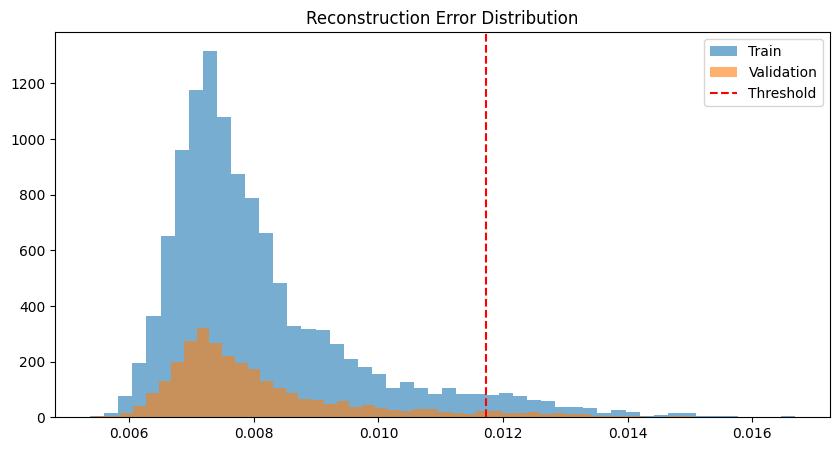

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.hist(train_errors, bins=50, alpha=0.6, label="Train")
plt.hist(val_errors, bins=50, alpha=0.6, label="Validation")
plt.axvline(threshold, color='red', linestyle='--', label="Threshold")
plt.legend()
plt.title("Reconstruction Error Distribution")
plt.show()

In [17]:
# Prepare full dataset (including degraded part)
full_features = train_df.drop(columns=["unit_number", "time_in_cycles", "RUL", "health_state"])
full_scaled = scaler.transform(full_features)
full_scaled_df = pd.DataFrame(full_scaled, columns=full_features.columns)

X_full = create_sequences(scaled_df, train_df["unit_number"].unique(), SEQ_LENGTH)

full_tensor = torch.tensor(X_full, dtype=torch.float32)
full_loader = DataLoader(TensorDataset(full_tensor), batch_size=64)

full_errors = get_reconstruction_error(full_loader)

print("Full error sample:", full_errors[:5])

Full error sample: [0.00655462 0.00652521 0.0065159  0.00668427 0.0066908 ]


In [18]:
anomalies = full_errors > threshold

print("Total sequences:", len(full_errors))
print("Anomalies detected:", np.sum(anomalies))

Total sequences: 17631
Anomalies detected: 430


In [19]:
sequence_info = []

for unit in train_df["unit_number"].unique():
    unit_data = train_df[train_df["unit_number"] == unit]
    
    for i in range(len(unit_data) - SEQ_LENGTH):
        sequence_info.append({
            "unit": unit,
            "start_cycle": unit_data.iloc[i]["time_in_cycles"],
            "end_cycle": unit_data.iloc[i + SEQ_LENGTH]["time_in_cycles"]
        })

sequence_df = pd.DataFrame(sequence_info)

sequence_df["error"] = full_errors
sequence_df["anomaly"] = sequence_df["error"] > threshold

sequence_df.head()

,unit,start_cycle,end_cycle,error,anomaly
0,1,1.0,31.0,0.006555,False
1,1,2.0,32.0,0.006525,False
2,1,3.0,33.0,0.006516,False
3,1,4.0,34.0,0.006684,False
4,1,5.0,35.0,0.006691,False


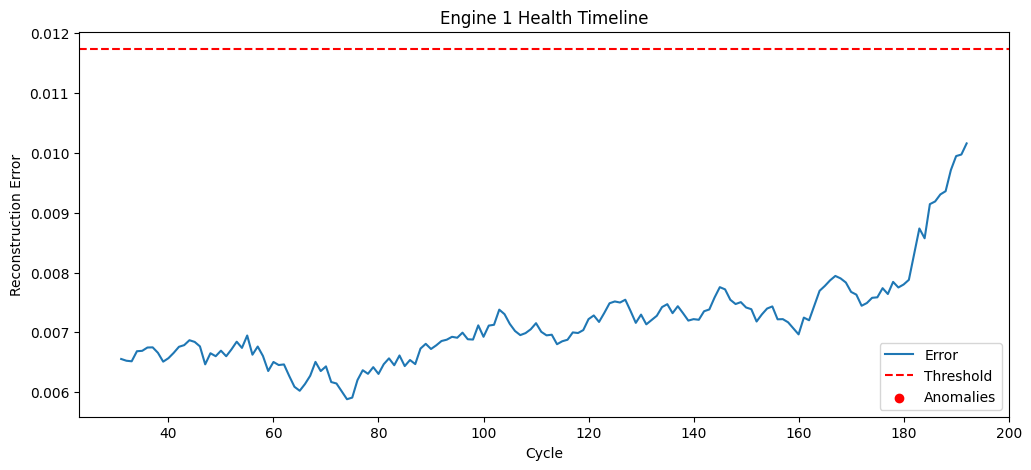

In [20]:
import matplotlib.pyplot as plt

unit_id = 1  # change later

unit_seq = sequence_df[sequence_df["unit"] == unit_id]

plt.figure(figsize=(12,5))

plt.plot(unit_seq["end_cycle"], unit_seq["error"], label="Error")

plt.axhline(threshold, color='red', linestyle='--', label="Threshold")

anomalies = unit_seq[unit_seq["anomaly"] == True]
plt.scatter(anomalies["end_cycle"], anomalies["error"], color='red', label="Anomalies")

plt.xlabel("Cycle")
plt.ylabel("Reconstruction Error")
plt.title(f"Engine {unit_id} Health Timeline")

plt.legend()
plt.show()

In [21]:
# Normalize error to create health score
max_error = sequence_df["error"].max()
min_error = sequence_df["error"].min()

sequence_df["health_score"] = 1 - ((sequence_df["error"] - min_error) / (max_error - min_error))

sequence_df["health_score"] = sequence_df["health_score"].clip(0,1)

sequence_df.head()

,unit,start_cycle,end_cycle,error,anomaly,health_score
0,1,1.0,31.0,0.006555,False,0.868148
1,1,2.0,32.0,0.006525,False,0.871032
2,1,3.0,33.0,0.006516,False,0.871945
3,1,4.0,34.0,0.006684,False,0.855431
4,1,5.0,35.0,0.006691,False,0.854790


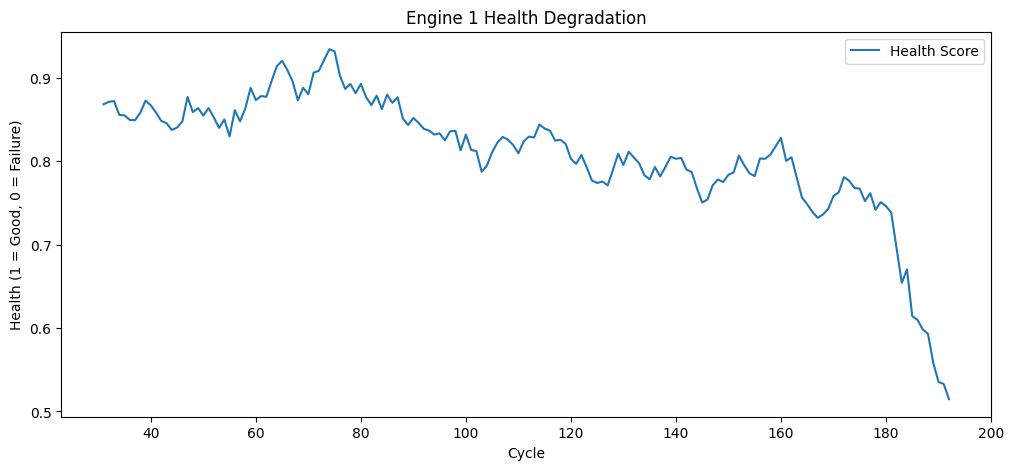

In [22]:
unit_id = 1

unit_seq = sequence_df[sequence_df["unit"] == unit_id]

plt.figure(figsize=(12,5))

plt.plot(unit_seq["end_cycle"], unit_seq["health_score"], label="Health Score")

plt.xlabel("Cycle")
plt.ylabel("Health (1 = Good, 0 = Failure)")
plt.title(f"Engine {unit_id} Health Degradation")

plt.legend()
plt.show()